# Sampling Distributions and the CLT (ABA Unit 2, Practical 6)

**Aim:** draw repeated samples from the sales data, study the sampling distribution of the mean, check the central limit theorem, and compare simple random with stratified sampling.

Run the cells in order (Runtime → Run all). Nothing to install. The note `sampling-distributions-practical` on Sutra explains every step.

In [1]:
# Step 1. The population: daily revenue on all 8,772 store-days
import numpy as np
import pandas as pd

url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
pop = df["revenue_inr"]
mu, sigma = pop.mean(), pop.std(ddof=0)
print(f"Population: N = {len(pop)}, mean Rs {mu:,.0f}, SD Rs {sigma:,.0f}, skewness {pop.skew():.2f}")

Population: N = 8772, mean Rs 444,043, SD Rs 336,298, skewness 1.26


In [2]:
# Step 2. Two simple random samples of 30 store-days give different means
rng = np.random.default_rng(2026)
for i in range(2):
    sample = rng.choice(pop.to_numpy(), size=30, replace=False)
    print(f"Sample {i + 1}: mean Rs {sample.mean():,.0f}")

Sample 1: mean Rs 438,289
Sample 2: mean Rs 420,304


In [3]:
# Step 3. 5,000 samples for each size: centre, spread and shape of the sample means
values = pop.to_numpy()
means = {}
for n in [5, 30, 100]:
    means[n] = np.array([rng.choice(values, size=n, replace=False).mean() for _ in range(5_000)])
    m = pd.Series(means[n])
    print(f"n = {n:>3}: mean of means Rs {m.mean():,.0f} | SD of means Rs {m.std():,.0f} "
          f"| sigma/sqrt(n) Rs {sigma / np.sqrt(n):,.0f} | skewness {m.skew():.2f}")

n =   5: mean of means Rs 448,287 | SD of means Rs 151,518 | sigma/sqrt(n) Rs 150,397 | skewness 0.58
n =  30: mean of means Rs 444,833 | SD of means Rs 62,538 | sigma/sqrt(n) Rs 61,399 | skewness 0.24
n = 100: mean of means Rs 444,073 | SD of means Rs 33,745 | sigma/sqrt(n) Rs 33,630 | skewness 0.16


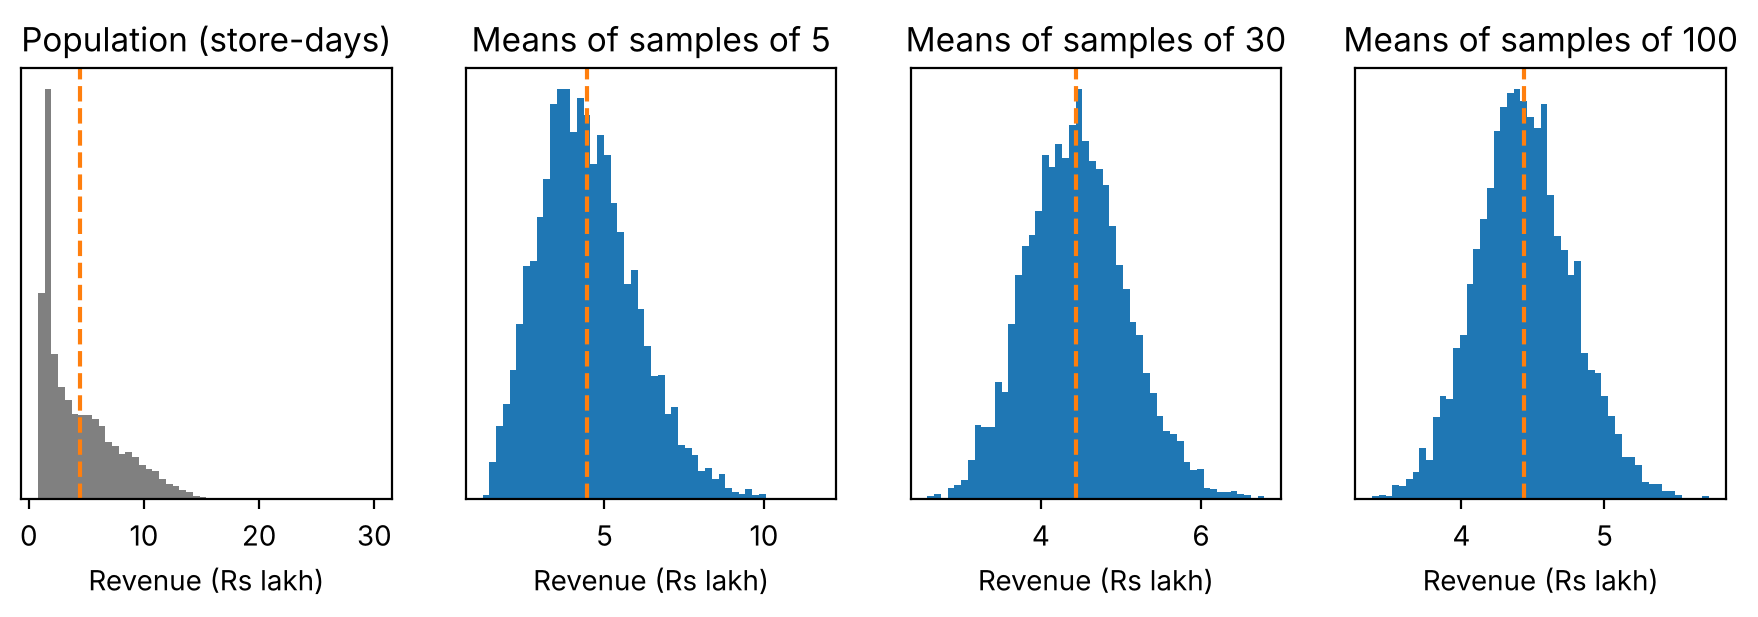

In [4]:
# Step 4. Plot: the population and the sampling distributions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
axes[0].hist(values / 1e5, bins=50, color="grey")
axes[0].set_title("Population (store-days)")
for ax, n in zip(axes[1:], [5, 30, 100]):
    ax.hist(means[n] / 1e5, bins=50, color="tab:blue")
    ax.set_title(f"Means of samples of {n}")
for ax in axes:
    ax.axvline(mu / 1e5, color="tab:orange", ls="--")
    ax.set_yticks([])
    ax.set_xlabel("Revenue (Rs lakh)")
plt.show()

In [5]:
# Step 5. Simple random vs stratified sampling (n = 60), 5,000 repetitions each
sm = df.loc[df["store_type"] == "Supermarket", "revenue_inr"].to_numpy()
ex = df.loc[df["store_type"] == "Express", "revenue_inr"].to_numpy()
n_sm = round(60 * len(sm) / len(pop))            # proportional allocation
n_ex = 60 - n_sm
srs = [rng.choice(values, 60, replace=False).mean() for _ in range(5_000)]
strat = [(rng.choice(sm, n_sm, replace=False).sum() + rng.choice(ex, n_ex, replace=False).sum()) / 60
         for _ in range(5_000)]
print(f"Allocation: {n_sm} Supermarket + {n_ex} Express store-days")
print(f"Simple random: mean Rs {np.mean(srs):,.0f}, SE Rs {np.std(srs, ddof=1):,.0f}")
print(f"Stratified   : mean Rs {np.mean(strat):,.0f}, SE Rs {np.std(strat, ddof=1):,.0f}")

Allocation: 25 Supermarket + 35 Express store-days
Simple random: mean Rs 443,885, SE Rs 42,843
Stratified   : mean Rs 443,856, SE Rs 25,528


In [6]:
# Step 6. Sampling distribution of a proportion: share of high-sales days in samples of 400
p90 = df.groupby("store_id")["revenue_inr"].transform(lambda s: s.quantile(0.9))
high = (df["revenue_inr"] > p90).astype(int).to_numpy()
p = high.mean()
props = np.array([rng.choice(high, 400, replace=False).mean() for _ in range(5_000)])
print(f"Population p = {p:.4f}")
print(f"Sample proportions: mean {props.mean():.4f}, SE {props.std(ddof=1):.4f} (formula {np.sqrt(p * (1 - p) / 400):.4f})")

Population p = 0.0999
Sample proportions: mean 0.1000, SE 0.0147 (formula 0.0150)
